# Robotics capstone 3: the full pipeline over a sequence - object map, consistency, latency

Notebooks 01 and 02 built and inspected the pipeline on single frames. A robot runs it
continuously while it moves, so this notebook runs the **complete pipeline** (text → boxes →
SAM masks → object clouds → table-aligned boxes → grasps) on every 8th frame of TUM `fr1/desk`
(72 frames spanning the whole 23 s sweep) and asks the questions that matter for deployment:

1. **Is it accurate?** There is no 3D object ground truth in TUM, but the objects are
   static and the camera pose is known from motion capture. So every frame's estimate of an
   object's world position should be the same point; the spread of these estimates around their
   median (**multi-frame consistency**) is a direct, label-free measure of 3D accuracy
   (it captures mask, depth, calibration and time-sync errors; a constant bias shared by all
   frames would stay invisible).
2. **Which design choices matter?** We ablate the mask source (SAM 3, SAM 2.1-S, no
   segmentation) and the camera model (with/without lens distortion, ROS default intrinsics)
   on exactly the same detections.
3. **Is it fast enough?** Per-stage latency and peak VRAM of the full pipeline.
4. **How do I inspect it?** Everything is logged to a [rerun](https://rerun.io) recording.

**What you'll learn**
- How to turn per-frame detections into a persistent **object map** (data association with a
  label + distance gate) and measure its consistency.
- How much segmentation quality and calibration actually matter for the 3D estimate.
- Where the time goes in a modern open-vocabulary perception stack on an 8 GB laptop GPU.

**Prerequisites**: notebooks 01 and 02.

## Setup

In [1]:
# --- Setup: imports, device, repo-relative paths and plotting style ---
# capstone.py: models, Pipeline, object map and consistency metric; grasp3d.py: geometry.
import os
import sys
import warnings

os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
warnings.filterwarnings("ignore", category=UserWarning)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import transformers
from IPython.display import display

from cvlab import device as cvdevice
from cvlab import viz
from cvlab.io import project_dir, repo_root, save_json

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()

PROJECT = "15_robotics_capstone"
sys.path.insert(0, str(project_dir(PROJECT) / "scripts"))
import capstone as cap  # noqa: E402
import grasp3d as g3  # noqa: E402

device = cvdevice.setup(seed=0)
viz.set_style()
DEV = "cuda" if device.type == "cuda" else "cpu"
QUERIES = cap.QUERIES
QCOL = {q: viz.color(k, unit=True) for k, q in enumerate(QUERIES)}

python 3.12.16 | torch 2.11.0+cu128 (CUDA 12.8) | torchvision 0.26.0+cu128 | numpy 2.5.4 | opencv 5.0.0
device: cuda | GPU: NVIDIA GeForce RTX 5060 Laptop GPU (7.53 GB, sm_120)


## 1. The sequence and the frames we process

`fr1/desk` has 573 RGB-D frames at 30 Hz with fast hand-held motion. We process every 8th
frame (≈ 3.7 Hz), which is a realistic rate for a pipeline that takes about a second per frame
and still sees every object many times. The camera pose $T_{wc}$ of each processed frame is the
motion-capture pose interpolated (linear + SLERP) at the depth image's timestamp.

In [2]:
# --- Select the frames and look at the camera trajectory ---
# Positions are camera centres in the motion-capture world frame [m].
frames = cap.load_frames()
STRIDE = 8
IDX = list(range(0, len(frames), STRIDE))
poses = {i: frames.pose(i, at="depth") for i in IDX}
all_pos = np.array([frames.pose(i)[:3, 3] for i in range(len(frames))])
t = frames.seq.timestamps
step = np.linalg.norm(np.diff(all_pos, axis=0), axis=1)
print(f"{len(frames)} frames over {t[-1] - t[0]:.1f} s; processing {len(IDX)} frames "
      f"(every {STRIDE}th, {len(IDX) / (t[-1] - t[0]):.2f} Hz)")
print(f"camera path length {step.sum():.2f} m, mean speed {step.sum() / (t[-1] - t[0]):.2f} m/s, "
      f"max {np.max(step / np.diff(t)):.2f} m/s")

573 frames over 19.8 s; processing 72 frames (every 8th, 3.63 Hz)
camera path length 9.30 m, mean speed 0.47 m/s, max 1.17 m/s


## 2. Pass 1: the complete pipeline with SAM 3, recorded to rerun

`cap.Pipeline` chains Grounding DINO-T → SAM 3 (box prompts) → the CPU 3D stage of notebook 02
and times every stage (GPU stages are CUDA-synchronised). One warm-up frame is excluded from the
timings. For every frame we also

- keep the boxes and masks in a cache (so the ablations below reuse **identical detections**),
- convert each object's box centre, centroid and best grasp to the world frame, and
- log the frame to a rerun recording: camera pose + pinhole, RGB, depth, segmentation,
  object points, oriented boxes and grasp arrows.

**Why no rerun screenshots?** The rerun viewer renders with the GPU in a window; it cannot
render an `.rrd` file to an image headless. The recording is the interactive deliverable
(`rerun outputs/15_robotics_capstone/capstone_fr1_desk.rrd`), and all figures in this project are
static matplotlib renders of the same data.

In [3]:
# --- Run Grounding DINO-T + SAM 3 + 3D stage over the 72 frames ---
# cache[i] holds boxes/scores/labels and the SAM 3 masks; obs collects world-frame observations.
K, D = cap.CAMERAS[cap.DEFAULT_CAMERA]
cvdevice.reset_peak_vram()
with cvdevice.track_vram() as mem:
    pipe = cap.Pipeline.create("gdino", "sam3", device=DEV)
    pipe(frames.rgb(IDX[0]), frames.depth(IDX[0]), QUERIES)  # warm-up
    rec = cap.RerunRecorder(cap.capstone_outputs() / "capstone_fr1_desk.rrd", K)
    cache, results, times, obs = {}, {}, {"SAM 3": []}, []
    for i in IDX:
        rgb, depth = frames.rgb(i), frames.depth(i)
        res, tt = pipe(rgb, depth, QUERIES)
        rec.log_frame(i, poses[i], rgb, depth, res)
        cache[i] = {"boxes": np.array([r.box2d for r in res]).reshape(-1, 4),
                    "scores": np.array([r.score for r in res]), "labels": [r.label for r in res],
                    "sam3": np.array([r.mask for r in res], dtype=bool).reshape(-1, 480, 640)}
        results[i] = res
        for o in cap.to_world(poses[i], res):
            o["frame"] = i
            obs.append(o)
        times["SAM 3"].append(tt)
vram = {"SAM 3": mem.peak_mb}
n_det = sum(len(c["labels"]) for c in cache.values())
print(f"{n_det} detections in {len(IDX)} frames, {len(obs)} with a 3D box; "
      f"peak VRAM {vram['SAM 3']:.0f} MiB")
print("mean stage times [ms]:", pd.DataFrame(times["SAM 3"]).mean().round(1).to_dict())

467 detections in 72 frames, 447 with a 3D box; peak VRAM 2731 MiB
mean stage times [ms]: {'detect_ms': 343.1, 'segment_ms': 348.9, 'cloud_ms': 110.9, 'box_ms': 120.4, 'grasp_ms': 162.5, 'total_ms': 1082.8}


## 3. Pass 2: the same pipeline with SAM 2.1-S

We swap the segmenter for SAM 2.1-S, keep Grounding DINO-T resident and run the full pipeline
again for its end-to-end timing and VRAM. Since the detector is deterministic up to GPU
floating-point noise, we also segment **pass 1's cached boxes** with SAM 2.1-S, so the
consistency comparison below differs only in the masks.

In [4]:
# --- Full pipeline with SAM 2.1-S (timing) + SAM 2.1-S masks for the cached boxes ---
# The image embedding set by the pipeline call is reused for the cached boxes.
pipe.segmenter = None
cap.free()
cvdevice.reset_peak_vram()
with cvdevice.track_vram() as mem:
    pipe.segmenter = cap.BoxSegmenter("sam2.1-s", DEV)
    pipe(frames.rgb(IDX[0]), frames.depth(IDX[0]), QUERIES)  # warm-up
    times["SAM 2.1-S"] = []
    for i in IDX:
        res2, tt = pipe(frames.rgb(i), frames.depth(i), QUERIES)
        times["SAM 2.1-S"].append(tt)
        cache[i]["sam2.1-s"], _ = pipe.segmenter.segment(cache[i]["boxes"])
vram["SAM 2.1-S"] = mem.peak_mb
del pipe, res2
cap.free()
cache_file = cap.save_mask_cache(cap.cache_path(), cache)
print(f"peak VRAM {vram['SAM 2.1-S']:.0f} MiB; mask cache: {cache_file.relative_to(repo_root())} "
      f"({cache_file.stat().st_size / 2**20:.1f} MiB)")
print("mean stage times [ms]:", pd.DataFrame(times["SAM 2.1-S"]).mean().round(1).to_dict())

peak VRAM 1942 MiB; mask cache: runs/15_robotics_capstone/fr1_desk_stride8_masks.npz (0.4 MiB)
mean stage times [ms]: {'detect_ms': 346.5, 'segment_ms': 80.0, 'cloud_ms': 109.4, 'box_ms': 121.6, 'grasp_ms': 164.9, 'total_ms': 819.7}


## 4. From observations to an object map

Each processed frame yields a set of **observations** (label, world-frame box centre). A
**landmark** is one physical object. Greedy association, frame by frame:

- candidate pairs = same label **and** distance to the landmark's running median < 15 cm;
- closest pairs are assigned first, at most one observation per landmark per frame;
- unmatched observations start new landmarks.

The running *median* (not mean) keeps a landmark from drifting towards outliers. Landmarks seen in
at least 5 frames are *stable*; the others are mostly false positives or objects seen only
briefly. For every stable landmark, the distance of each observation to the landmark's median is
the **consistency error**.

In [5]:
# --- Build the object map of pass 1 and measure per-landmark consistency ---
# landmark_stats: median / RMS / 90th-percentile distance of observations to the landmark median.
landmarks = cap.build_object_map(obs, key="box_center_w", gate=0.15)
stats = cap.landmark_stats(landmarks, key="box_center_w", min_obs=5)
rows = []
for s in stats:
    lm = landmarks[s["landmark"]]
    ext = np.median([o["extents"] for o in lm["obs"]], axis=0)
    rows.append({"landmark": s["landmark"], "label": s["label"], "frames seen": s["n_obs"],
                 "median dev [cm]": round(s["median_dev_cm"], 1),
                 "p90 dev [cm]": round(s["p90_dev_cm"], 1),
                 "within 5 cm [%]": round(100 * s["frac_within_5cm"], 0),
                 "median extents [cm]": np.round(100 * ext, 1),
                 "frames with a grasp [%]": round(100 * np.mean([o["grasp_T_w"] is not None
                                                                 for o in lm["obs"]]), 0)})
lm_df = pd.DataFrame(rows).set_index("landmark").sort_values("frames seen", ascending=False)
display(lm_df)
base = cap.consistency(obs, key="box_center_w")
print({k: round(v, 1) for k, v in base.items()})

,label,frames seen,median dev [cm],p90 dev [cm],within 5 cm [%],median extents [cm],frames with a grasp [%]
landmark,,,,,,,
8,cup,39,2.9,6.1,85.0,"[8.4, 5.8, 9.8]",79.0
10,cereal box,36,1.8,5.6,89.0,"[11.0, 7.2, 18.4]",67.0
11,book,34,1.4,3.9,91.0,"[24.6, 16.7, 4.1]",21.0
0,keyboard,27,2.7,12.7,78.0,"[43.7, 18.0, 3.9]",22.0
16,game controller,26,2.0,3.7,100.0,"[14.1, 7.3, 6.4]",85.0
20,telephone,26,2.2,5.6,81.0,"[22.8, 17.6, 11.6]",27.0
1,computer mouse,22,3.2,5.3,86.0,"[8.9, 3.8, 2.5]",82.0
13,game controller,21,1.2,2.9,100.0,"[15.7, 6.8, 3.3]",100.0
12,book,19,2.6,9.1,79.0,"[25.4, 19.5, 6.7]",32.0


{'observations': 447, 'landmarks': 65, 'stable landmarks': 21, 'obs in stable landmarks [%]': 85.5, 'median dev [cm]': 2.1, 'p90 dev [cm]': 6.2, 'within 5 cm [%]': 85.3}


## 5. Ablations: what matters for the 3D estimate?

All variants reuse pass 1's detections and only re-run the CPU 3D stage:

| variant | masks | camera model |
|---|---|---|
| baseline | SAM 3 | fr1 calibration + distortion |
| SAM 2.1-S | SAM 2.1-S | fr1 + distortion |
| no segmentation | the filled 2D box | fr1 + distortion |
| no distortion | SAM 3 | fr1 $K$, distortion ignored |
| ROS default | SAM 3 | $f = 525$, no distortion |

We also compare the two position estimates of the baseline: the **box centre** (gravity-aligned
box, extruded to the table) and the **centroid** of the visible points, which moves with the
viewpoint because the camera only sees the front/top surfaces.

In [6]:
# --- Re-run the 3D stage for every variant and compare consistency ---
# sequence_observations() re-uses the cached boxes/masks; only the CPU geometry runs here.
variants = {"baseline (SAM 3, fr1 + distortion)": obs}
for name, kw in {"SAM 2.1-S masks": {"mask_key": "sam2.1-s"},
                 "no segmentation (box mask)": {"mask_key": "box"},
                 "fr1 K, distortion ignored": {"camera": "fr1, no distortion"},
                 "ROS default intrinsics": {"camera": "ROS default"}}.items():
    variants[name], _ = cap.sequence_observations(frames, cache, **kw)
rows = []
for name, o in variants.items():
    rows.append({"variant": name, "position": "box centre", **cap.consistency(o, key="box_center_w")})
rows.append({"variant": "baseline (SAM 3, fr1 + distortion)", "position": "visible-point centroid",
             **cap.consistency(obs, key="centroid_w")})
abl_df = pd.DataFrame(rows).set_index(["variant", "position"]).round(1)
display(abl_df)

,,observations,landmarks,stable landmarks,obs in stable landmarks [%],median dev [cm],p90 dev [cm],within 5 cm [%]
variant,position,,,,,,,
"baseline (SAM 3, fr1 + distortion)",box centre,447,65,21,85.5,2.1,6.2,85.3
SAM 2.1-S masks,box centre,447,64,21,86.4,2.2,6.2,83.9
no segmentation (box mask),box centre,451,68,20,84.3,3.4,8.2,68.9
"fr1 K, distortion ignored",box centre,447,64,20,85.7,2.2,6.1,85.4
ROS default intrinsics,box centre,447,64,20,85.9,2.2,6.1,85.9
"baseline (SAM 3, fr1 + distortion)",visible-point centroid,447,64,19,85.0,2.3,6.2,85.5


## 6. Static renders of the object map

The figure shows the map from above: "up" is estimated as the median support-plane normal of all
objects, rotated into the world frame (it is not assumed from the motion-capture convention). Small
dots are per-frame observations coloured by label, crosses are stable landmark positions, and the
grey line is the camera trajectory.

402 support-plane normals; up (world) = [ 0.006 -0.031  1.   ], median deviation 2.3 deg


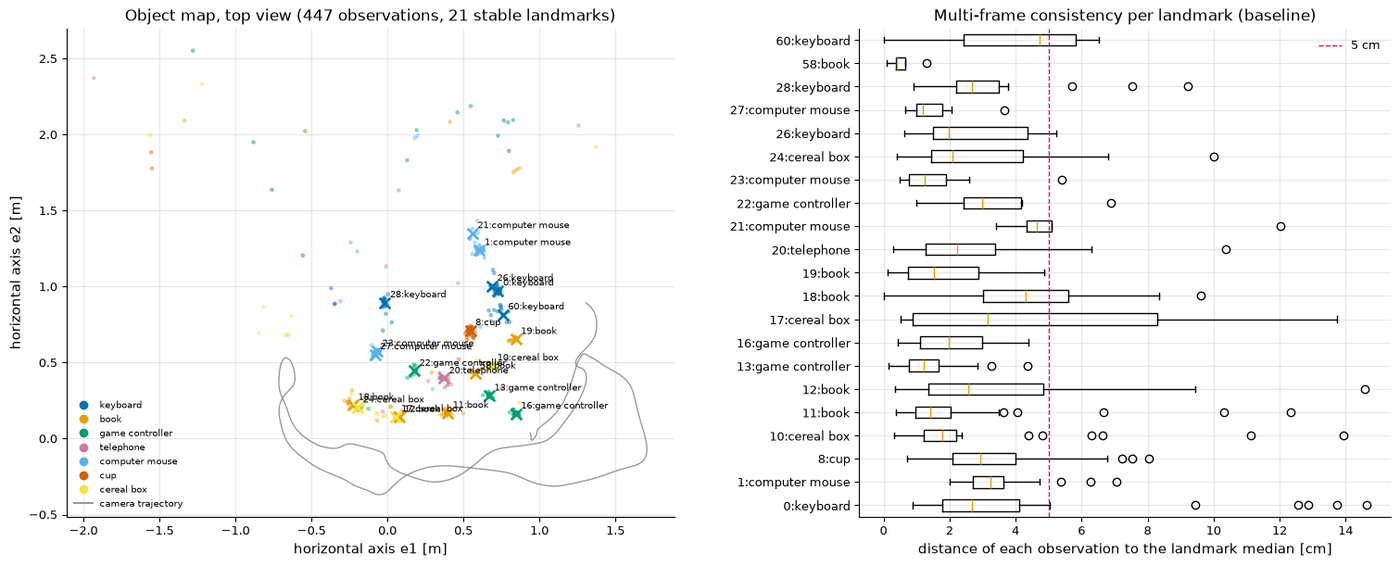

In [7]:
# --- Top view of the object map and the per-landmark spread ---
# up = median desk normal in the world frame; e1, e2 span the horizontal plane.
n_w = np.array([poses[i][:3, :3] @ r.plane.normal for i in IDX for r in results[i] if r.plane is not None])
up = np.median(n_w, axis=0)
up /= np.linalg.norm(up)
print(f"{len(n_w)} support-plane normals; up (world) = {np.round(up, 3)}, "
      f"median deviation {np.median(np.degrees(np.arccos(np.clip(n_w @ up, -1, 1)))):.1f} deg")
e1, e2 = g3.in_plane_basis(up)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.3, 1]})
ax.plot(all_pos @ e1, all_pos @ e2, color="0.6", lw=1, label="camera trajectory")
P = np.array([o["box_center_w"] for o in obs])
ax.scatter(P @ e1, P @ e2, s=6, alpha=0.35, c=[QCOL[o["label"]] for o in obs])
for s in stats:
    p = s["position"]
    ax.scatter(p @ e1, p @ e2, marker="x", s=70, color=QCOL[s["label"]], linewidths=2)
    ax.annotate(f"{s['landmark']}:{s['label']}", (p @ e1, p @ e2), fontsize=7,
                xytext=(4, 4), textcoords="offset points")
handles = [plt.Line2D([], [], ls="", marker="o", color=QCOL[q], label=q) for q in QUERIES]
ax.legend(handles=handles + [plt.Line2D([], [], color="0.6", label="camera trajectory")],
          fontsize=7, loc="best")
ax.set_aspect("equal")
ax.set_xlabel("horizontal axis e1 [m]")
ax.set_ylabel("horizontal axis e2 [m]")
ax.set_title(f"Object map, top view ({len(obs)} observations, {len(stats)} stable landmarks)")
data = []
for s in stats:
    lm = landmarks[s["landmark"]]
    Q = np.array([o["box_center_w"] for o in lm["obs"]])
    data.append(100 * np.linalg.norm(Q - np.median(Q, axis=0), axis=1))
ax2.boxplot(data, orientation="horizontal", tick_labels=[f"{s['landmark']}:{s['label']}" for s in stats])
ax2.axvline(5, color="crimson", ls="--", lw=1, label="5 cm")
ax2.set_xlabel("distance of each observation to the landmark median [cm]")
ax2.set_title("Multi-frame consistency per landmark (baseline)")
ax2.legend()
viz.savefig(fig, PROJECT, "object_map")
plt.show()

## 7. A thumbnail of the pipeline output

For the project overview we render one close-up frame of the sweep (masks, projected 3D boxes
and the best grasp of every object).

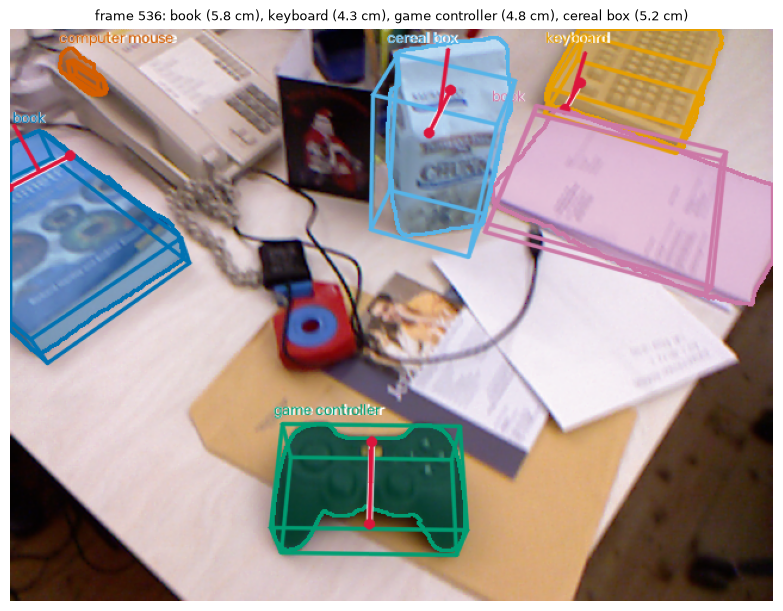

In [8]:
# --- Render the processed frame closest to frame 540 and save a small thumbnail ---
# The thumbnail (about 400 px wide) is used in the repository overview table.
best_frame = min(IDX, key=lambda i: abs(i - 540))
img = cap.draw_results(frames.rgb(best_frame), results[best_frame], K, D)
fig, ax = plt.subplots(figsize=(3.4, 2.55))
ax.imshow(img)
ax.axis("off")
viz.savefig(fig, PROJECT, "thumb")
plt.close(fig)
fig, ax = plt.subplots(figsize=(8, 6))
ax.imshow(img)
ax.axis("off")
ax.set_title(f"frame {best_frame}: " + ", ".join(
    f"{r.label} ({100 * r.best_grasp.width:.1f} cm)" for r in results[best_frame] if r.best_grasp is not None),
    fontsize=9)
plt.show()

## 8. The rerun recording

The recording now holds every processed frame; we add the stable landmarks and close it. Open it
with the viewer that matches the SDK version (rerun 0.42, `.rrd` files are not compatible across
versions): `rerun outputs/15_robotics_capstone/capstone_fr1_desk.rrd`.

In [9]:
# --- Add the object map to the recording and close it ---
# The file is in outputs/ (gitignored); its size grows with the number of logged frames.
rec.log_map(stats, IDX[-1])
rrd = rec.close()
print(f"rerun recording: {rrd.relative_to(repo_root())}, {rrd.stat().st_size / 2**20:.1f} MiB, "
      f"{len(IDX)} frames")

rerun recording: outputs/15_robotics_capstone/capstone_fr1_desk.rrd, 26.0 MiB, 72 frames


## Results

Per-stage latency over the 72 processed frames (RTX 5060 Laptop GPU 8 GB for the models, Intel
Core Ultra 9 275HX for the NumPy/SciPy geometry), and the consistency of each variant.

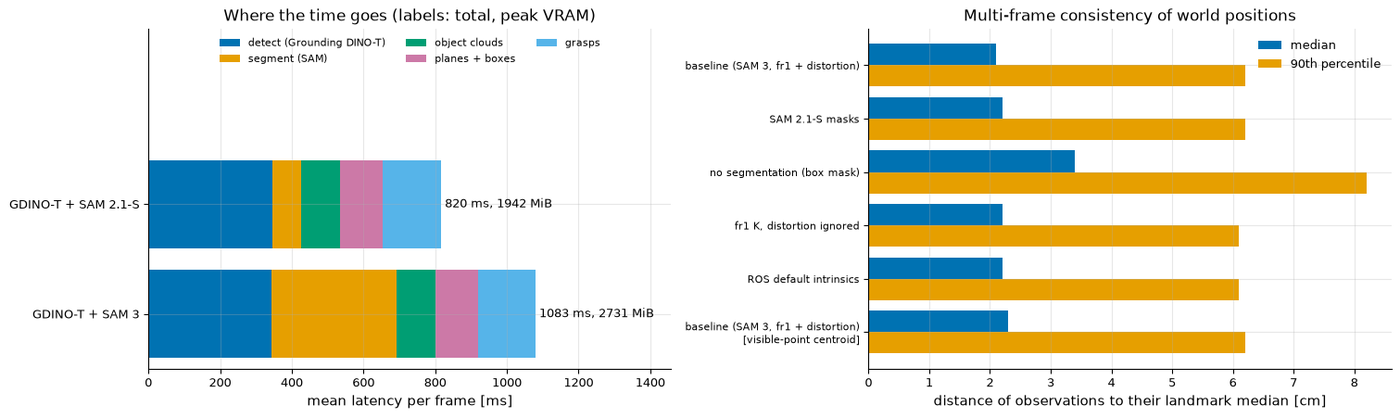

mean [ms]  p50 [ms]  p90 [ms]
pipeline            stage                                                   
GDINO-T + SAM 3     detect (Grounding DINO-T)      343.1     336.7     371.6
                    segment (SAM)                  348.9     352.4     368.6
                    object clouds                  109.3      94.6     193.8
                    planes + boxes                 118.7     125.3     172.4
                    grasps                         160.3     161.5     252.6
                    total                         1082.8    1102.0    1305.9
GDINO-T + SAM 2.1-S detect (Grounding DINO-T)      346.5     337.8     374.6
                    segment (SAM)                   80.0      82.5      89.2
                    object clouds                  107.9      93.0     187.7
                    planes + boxes                 119.9     124.7     176.5
                    grasps                         162.7     163.5     257.0
                    total                          819.7     827.7    1001.0

In [10]:
# --- Latency per stage and consistency per variant ---
# Stage times are per frame; the 3D stages scale with the number of objects in the frame.
stages = ["detect_ms", "segment_ms", "cloud_ms", "box_ms", "grasp_ms"]
names = {"detect_ms": "detect (Grounding DINO-T)", "segment_ms": "segment (SAM)",
         "cloud_ms": "object clouds", "box_ms": "planes + boxes", "grasp_ms": "grasps"}
lat_rows = []
for pipe_name, tt in times.items():
    df = pd.DataFrame(tt).fillna(0.0)
    for s in stages + ["total_ms"]:
        lat_rows.append({"pipeline": f"GDINO-T + {pipe_name}", "stage": names.get(s, "total"),
                         "mean [ms]": df[s].mean(), "p50 [ms]": df[s].median(),
                         "p90 [ms]": df[s].quantile(0.9)})
lat_df = pd.DataFrame(lat_rows).set_index(["pipeline", "stage"]).round(1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.4))
left = np.zeros(len(times))
for k, s in enumerate(stages):
    vals = np.array([pd.DataFrame(tt).fillna(0.0)[s].mean() for tt in times.values()])
    ax1.barh(list(range(len(times))), vals, left=left, color=viz.color(k, unit=True), label=names[s])
    left += vals
for j, (pn, tt) in enumerate(times.items()):
    ax1.text(left[j] + 10, j, f"{pd.DataFrame(tt)['total_ms'].mean():.0f} ms, {vram[pn]:.0f} MiB",
             va="center", fontsize=9)
ax1.set_yticks(range(len(times)), [f"GDINO-T + {n}" for n in times])
ax1.set_xlim(0, left.max() * 1.35)
ax1.set_ylim(-0.5, 2.6)
ax1.set_xlabel("mean latency per frame [ms]")
ax1.set_title("Where the time goes (labels: total, peak VRAM)")
ax1.legend(fontsize=8, loc="upper center", ncol=3)
sub = abl_df.reset_index()
lab = [f"{v}\n[{p}]" if p != "box centre" else v for v, p in zip(sub["variant"], sub["position"])]
y = np.arange(len(sub))
ax2.barh(y - 0.2, sub["median dev [cm]"], height=0.4, color=viz.color(0, unit=True), label="median")
ax2.barh(y + 0.2, sub["p90 dev [cm]"], height=0.4, color=viz.color(1, unit=True), label="90th percentile")
ax2.set_yticks(y, lab, fontsize=8)
ax2.invert_yaxis()
ax2.set_xlabel("distance of observations to their landmark median [cm]")
ax2.set_title("Multi-frame consistency of world positions")
ax2.legend()
viz.savefig(fig, PROJECT, "latency_consistency")
plt.show()
display(lat_df)

The ablation table above is the accuracy summary; the latency table and the per-variant
consistency are also written to `results/nb03_sequence.json` for the README.

In [11]:
# --- Save the measured numbers (small JSON, committed) ---
summary = {
    "frames": len(IDX), "stride": STRIDE, "detections": n_det, "observations_3d": len(obs),
    "peak_vram_mib": {k: round(v) for k, v in vram.items()},
    "latency_ms": {f"{p} | {s}": {c: float(lat_df.loc[(p, s), c]) for c in lat_df.columns}
                   for p, s in lat_df.index},
    "consistency": {f"{v} | {p}": {c: float(abl_df.loc[(v, p), c]) for c in abl_df.columns}
                    for v, p in abl_df.index},
    "landmarks": lm_df.reset_index().drop(columns=["median extents [cm]"]).to_dict(orient="records"),
}
out = save_json(summary, cap.results_dir() / "nb03_sequence.json")
print("wrote", out.relative_to(repo_root()))
summary_df = pd.DataFrame({
    "metric": ["frames processed", "detections", "objects with a 3D box", "stable landmarks",
               "median consistency error [cm]", "p90 consistency error [cm]",
               "end-to-end latency, SAM 3 [ms]", "end-to-end latency, SAM 2.1-S [ms]",
               "peak VRAM, SAM 3 pipeline [MiB]", "peak VRAM, SAM 2.1-S pipeline [MiB]"],
    "value": [len(IDX), n_det, len(obs), base["stable landmarks"], round(base["median dev [cm]"], 1),
              round(base["p90 dev [cm]"], 1),
              round(lat_df.loc[("GDINO-T + SAM 3", "total"), "mean [ms]"], 1),
              round(lat_df.loc[("GDINO-T + SAM 2.1-S", "total"), "mean [ms]"], 1),
              round(vram["SAM 3"]), round(vram["SAM 2.1-S"])]}).set_index("metric")
display(summary_df)

wrote projects/15_robotics_capstone/results/nb03_sequence.json


,value
metric,
frames processed,72.0
detections,467.0
objects with a 3D box,447.0
stable landmarks,21.0
median consistency error [cm],2.1
p90 consistency error [cm],6.2
"end-to-end latency, SAM 3 [ms]",1082.8
"end-to-end latency, SAM 2.1-S [ms]",819.7
"peak VRAM, SAM 3 pipeline [MiB]",2731.0


### Takeaways

- **Accuracy without labels.** Of 467 detections in 72 frames, 447 gave a 3D box. They form 65
  landmarks; the 21 seen in at least 5 frames hold 85.5 % of the observations, and their world
  positions scatter by a median of **2.1 cm** around the landmark medians (90th percentile 6.2 cm,
  85.3 % within 5 cm), while the hand-held camera moves 9.3 m at up to 1.17 m/s. With 1 cm of
  clearance per finger, errors of this size are only marginally acceptable for an open-loop grasp;
  a real robot re-detects during the final approach (closed loop).
- **Segmentation matters, the choice of segmenter much less.** Using the filled 2D box as the
  mask raises the median error to 3.4 cm and the 90th percentile to 8.2 cm (only 68.9 % within
  5 cm): desk and background pixels inside the box pull the depth and the footprint. SAM 2.1-S
  masks are as good as SAM 3 masks for this purpose (2.2 cm / 6.2 cm).
- **The camera model is not the bottleneck here.** Ignoring the fr1 lens distortion or using
  the ROS default intrinsics changes the consistency by at most 0.1 cm, although notebook 02
  showed up to 3 cm of lateral ray difference at 1 m in the image corners: mask and depth noise
  dominate. The metric's blind spot is a bias shared by all frames, which it cannot see.
- **Box centre vs centroid**: the gravity-aligned box centre is a little more stable than the
  centroid of the visible points (2.1 vs 2.3 cm median), which shifts towards the faces the
  camera currently sees.
- **Map hygiene is the weak point.** Landmarks 0 and 26 are the same keyboard (their medians end
  up 5.4 cm apart; greedy online association never merges landmarks once they exist), and
  landmarks 17 and 24 are books labelled *cereal box* (book-sized boxes). Per-frame
  open-vocabulary output needs tracking, label voting and 3D-overlap association before a robot
  can trust the map; the exercises explore the gate and a score threshold.
- **Latency**: Grounding DINO-T + SAM 3 takes 1082.8 ms per frame on average (2731 MiB
  peak VRAM), the SAM 2.1-S variant 819.7 ms (1942 MiB). Grounding DINO-T is the largest
  GPU cost (346.5 ms), and the single-threaded NumPy/SciPy geometry (clouds, planes + boxes,
  grasps: 390.5 ms in the SAM 2.1-S run) costs about as much as the models: the first thing to
  optimise (vectorise, parallelise per object, down-sample before the KD-trees). CPU stage times
  vary from run to run of this notebook because the machine was shared with other jobs.

## Exercises

These exercises are CPU-only: they reuse the mask cache this notebook wrote to
`runs/15_robotics_capstone/` (`cap.load_mask_cache()`), so run this notebook first.

**Exercise 1 - the association gate.** Rebuild the object map with gates of 5, 10, 15 and 30 cm.
How do the number of stable landmarks and the consistency error change? What goes wrong at each end?

In [12]:
# --- Exercise 1: association gate sweep (TODO) ---
# TODO: for gate in [0.05, 0.10, 0.15, 0.30]: cap.consistency(obs, gate=gate)

**Exercise 2 - time synchronisation.** The 3D points come from the depth image, but it is tempting
to use the pose at the RGB timestamp (up to 20 ms earlier or later). Re-run the 3D stage with
`pose_at="rgb"` and compare the consistency. How far does the camera move in 20 ms at this
sequence's speed?

In [13]:
# --- Exercise 2: pose at the RGB vs the depth timestamp (TODO) ---
# TODO: obs_rgb, _ = cap.sequence_observations(frames, cache, pose_at="rgb"); compare
#       cap.consistency(obs_rgb) with cap.consistency(obs).

**Exercise 3 - confidence filtering.** Keep only detections with score ≥ 0.5 (`min_score=0.5`).
Does the map get cleaner (fewer unstable landmarks)? What does it cost in observations?

In [14]:
# --- Exercise 3: score threshold before the 3D stage (TODO) ---
# TODO: obs_hi, _ = cap.sequence_observations(frames, cache, min_score=0.5) and compare.